# HidroClima Ecuador · Proyecto Integrador Avance II: Modelos de clasificación
**Asignatura:** Machine Learning · **Integrantes:** Zayo Vieria, Marlon Benavides, Martin Andrade

**Pregunta:** con los datos de hoy, ¿lloverán mañana 6 mm o más en la cuenca del río Paute? Desde 6 mm el caudal que llega al embalse Mazar sube al menos en la mitad de los días, por eso se toma como lluvia importante.

Se entrenan y comparan tres algoritmos de clasificación: **regresión logística, máquinas de soporte vectorial (SVM) y árbol de decisión**.

Contenido:
1. Dataset y preparación de los datos
2. Funciones de evaluación y modelos de referencia
3. Regresión logística
4. SVM
5. Árbol de decisión
6. Comparación e interpretación de resultados
7. Avances y sugerencias de las sesiones 1 a 1
8. Conclusiones

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Dataset y preparación de los datos

### 1.1 Carga del dataset
Se usa el dataset preparado en el avance de **Prácticas y Herramientas de Big Data (Parte 2)**, `hidroclima_mazar_preparado.csv`. Tiene 4.011 días, de 2015 a 2025, de la cuenca del río Paute. Cada día es el promedio de 6 puntos de Open-Meteo (Cajas, Chiquintad, Cuenca, Azogues, Gualaceo y Mazar), unido con el caudal diario del río Paute. El objetivo `lluvia_manana` ya viene construido con el umbral de 6 mm.

**Relación con el dataset del Avance I.** Se mantiene la misma fuente, la API Historical Weather de Open-Meteo, el mismo periodo de 2015 a 2025 y las mismas variables meteorológicas. Lo que cambió fue la forma de armarlo, siguiendo las sesiones 1 a 1: en el Avance I había un solo punto en dos zonas distintas, Coca Codo Sinclair y Mazar, con un umbral de 5 mm. Ahora se usan 6 puntos de la cuenca que alimenta a Mazar, se agrega el caudal del río y el umbral de 6 mm se justifica con la respuesta del caudal. El detalle está en la sección 7.

**Cómo se ejecuta.** Si el archivo CSV está junto al notebook, se lee directamente. Si no está, el notebook vuelve a descargar los datos de las APIs de Open-Meteo y repite la misma preparación del notebook de Big Data, así que se puede ejecutar en Colab sin subir ningún archivo.

In [2]:
NOMBRE_CSV = "hidroclima_mazar_preparado.csv"
URL_CLIMA = "https://archive-api.open-meteo.com/v1/archive"
URL_CAUDAL = "https://flood-api.open-meteo.com/v1/flood"
VARIABLES = ("temperature_2m_max,temperature_2m_min,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,"
             "wind_speed_10m_max,shortwave_radiation_sum,pressure_msl_mean,cloud_cover_mean")
PUNTOS = {"Cajas": (-2.80, -79.20), "Chiquintad": (-2.78, -79.00), "Cuenca": (-2.90, -79.00),
          "Azogues": (-2.74, -78.85), "Gualaceo": (-2.89, -78.78), "Mazar": (-2.59, -78.63)}
FECHAS = {"start_date": "2015-01-01", "end_date": "2025-12-31"}

def consultar(url, params):
    # Reintenta si la API responde 429 (demasiadas consultas) y revisa el código de respuesta
    for intento in range(5):
        respuesta = requests.get(url, params=params, timeout=60)
        if respuesta.status_code != 429:
            break
        time.sleep(60)
    respuesta.raise_for_status()
    return pd.DataFrame(respuesta.json()["daily"])

def construir_dataset():
    # Misma preparación del notebook de Big Data Parte 2
    clima = pd.concat([consultar(URL_CLIMA, {"latitude": lat, "longitude": lon, "daily": VARIABLES,
                                             "timezone": "America/Guayaquil", **FECHAS}).assign(punto=p)
                       for p, (lat, lon) in PUNTOS.items()])
    clima = clima.rename(columns={"time": "fecha", "temperature_2m_max": "temp_max", "temperature_2m_min": "temp_min",
                                  "precipitation_sum": "precipitacion", "precipitation_hours": "horas_precipitacion",
                                  "relative_humidity_2m_mean": "humedad_media", "wind_speed_10m_max": "viento_max",
                                  "shortwave_radiation_sum": "radiacion", "pressure_msl_mean": "presion_media",
                                  "cloud_cover_mean": "nubosidad_media"})
    caudal = consultar(URL_CAUDAL, {"latitude": -2.59, "longitude": -78.63, "daily": "river_discharge", **FECHAS})
    caudal = caudal.rename(columns={"time": "fecha", "river_discharge": "caudal"})
    clima["fecha"] = pd.to_datetime(clima["fecha"])
    caudal["fecha"] = pd.to_datetime(caudal["fecha"])
    cuenca = clima.groupby("fecha").agg(
        precipitacion=("precipitacion", "mean"), precip_max=("precipitacion", "max"),
        horas_precipitacion=("horas_precipitacion", "mean"), humedad_media=("humedad_media", "mean"),
        nubosidad_media=("nubosidad_media", "mean"), temp_max=("temp_max", "mean"), temp_min=("temp_min", "mean"),
        presion_media=("presion_media", "mean"), radiacion=("radiacion", "mean"),
        viento_max=("viento_max", "mean")).reset_index()
    cuenca = cuenca.merge(caudal, on="fecha")
    cuenca["mes"] = cuenca["fecha"].dt.month
    cuenca["lluvia_7d"] = cuenca["precipitacion"].rolling(7).sum()
    cuenca["precip_manana"] = cuenca["precipitacion"].shift(-1)
    cuenca["lluvia_manana"] = (cuenca["precip_manana"] >= 6).astype(int)
    return cuenca.dropna()

def cargar_dataset():
    for ruta in [Path(NOMBRE_CSV), Path("data") / NOMBRE_CSV, Path("../data") / NOMBRE_CSV]:
        if ruta.exists():
            print("Fuente:", ruta)
            datos = pd.read_csv(ruta, parse_dates=["fecha"])
            break
    else:
        print("Fuente: APIs de Open-Meteo (no se encontró el CSV)")
        datos = construir_dataset()
    return datos.sort_values("fecha").reset_index(drop=True)

df = cargar_dataset()
print(df.shape)
df.head()

Fuente: hidroclima_mazar_preparado.csv
(4011, 16)


,fecha,precipitacion,precip_max,horas_precipitacion,humedad_media,nubosidad_media,temp_max,temp_min,presion_media,radiacion,viento_max,caudal,mes,lluvia_7d,precip_manana,lluvia_manana
0,2015-01-07,2.550,6.8,8.500,88.667,82.167,14.617,9.467,1016.850,12.078,10.833,152.11,1,21.150,2.133,0
1,2015-01-08,2.133,4.1,8.167,85.500,62.667,15.600,9.417,1016.783,17.450,11.700,149.31,1,19.467,10.883,1
2,2015-01-09,10.883,15.8,17.667,92.667,88.333,15.417,10.850,1017.617,11.668,10.017,168.82,1,28.250,5.500,0
3,2015-01-10,5.500,13.9,12.167,88.667,73.167,15.617,10.300,1018.483,14.208,11.600,169.61,1,31.367,2.217,0
4,2015-01-11,2.217,3.4,8.167,87.333,75.667,16.300,9.517,1018.167,17.890,12.083,160.44,1,28.950,2.050,0


In [3]:
# Comprobaciones: mismo dataset que el avance de Big Data
assert df.shape == (4011, 16)
assert df["lluvia_manana"].value_counts().to_dict() == {0: 2689, 1: 1322}
assert df.isna().sum().sum() == 0
assert (df["fecha"].diff().dt.days.dropna() == 1).all()
assert (df["lluvia_manana"] == (df["precip_manana"] >= 6).astype(int)).all()
print("Dataset verificado: 4.011 días consecutivos, sin faltantes, 1.322 positivos.")

Dataset verificado: 4.011 días consecutivos, sin faltantes, 1.322 positivos.


### 1.2 Variables predictoras
Se usan las 13 características definidas en el avance de Big Data, todas medidas **el día actual**. La columna `fecha` solo identifica el día, y `precip_manana` y `lluvia_manana` describen el día que se quiere predecir, así que quedan fuera de los predictores para evitar fuga de información.

In [4]:
PREDICTORES = ["precipitacion", "precip_max", "horas_precipitacion", "humedad_media", "nubosidad_media",
               "temp_max", "temp_min", "presion_media", "radiacion", "viento_max", "caudal", "lluvia_7d", "mes"]
OBJETIVO = "lluvia_manana"
print(len(PREDICTORES), "predictores")

13 predictores


### 1.3 División temporal en tres periodos
La partición se hace por la fecha del día que se predice (mañana), en orden cronológico:

- **Entrenamiento (2015 a 2020):** se ajustan los modelos.
- **Validación (2021 a 2022):** se eligen los hiperparámetros y el umbral de decisión de cada modelo.
- **Prueba (2023 a 2025):** se usa una sola vez al final, después de reentrenar con 2015 a 2022. Es el mismo corte de 2023 usado en el Avance I.

No se usa una división aleatoria porque el modelo debe predecir días futuros con información del pasado. Si los hiperparámetros y el umbral se eligieran mirando la prueba, sus métricas saldrían infladas.

In [5]:
fecha_objetivo = df["fecha"] + pd.Timedelta(days=1)
es_tr = fecha_objetivo < pd.Timestamp("2021-01-01")
es_val = (~es_tr) & (fecha_objetivo < pd.Timestamp("2023-01-01"))
es_te = fecha_objetivo >= pd.Timestamp("2023-01-01")

X_tr, y_tr = df.loc[es_tr, PREDICTORES], df.loc[es_tr, OBJETIVO]
X_val, y_val = df.loc[es_val, PREDICTORES], df.loc[es_val, OBJETIVO]
X_trval, y_trval = df.loc[es_tr | es_val, PREDICTORES], df.loc[es_tr | es_val, OBJETIVO]
X_te, y_te = df.loc[es_te, PREDICTORES], df.loc[es_te, OBJETIVO]
test = df.loc[es_te].copy()

particion = pd.DataFrame([
    {"Conjunto": nombre, "Primer día predicho": fecha_objetivo[m].min().date(),
     "Último día predicho": fecha_objetivo[m].max().date(), "Días": int(m.sum()),
     "% con lluvia ≥ 6 mm": round(100 * df.loc[m, OBJETIVO].mean(), 1)}
    for nombre, m in [("Entrenamiento", es_tr), ("Validación", es_val), ("Prueba", es_te)]])
particion

,Conjunto,Primer día predicho,Último día predicho,Días,% con lluvia ≥ 6 mm
0,Entrenamiento,2015-01-08,2020-12-31,2185,31.6
1,Validación,2021-01-01,2022-12-31,730,34.0
2,Prueba,2023-01-01,2025-12-31,1096,35.0


### 1.4 Preprocesamiento
La regresión logística y la SVM dependen de la escala de las variables (el caudal está en cientos de m³/s y la lluvia en mm), por eso se **estandarizan**. Además, el mes se convierte en dos variables cíclicas (seno y coseno), porque como número diciembre (12) y enero (1) quedarían lejos aunque sean meses vecinos y ambos lluviosos. El árbol de decisión no necesita escalado y usa el mes tal cual. El preprocesamiento va dentro de un `Pipeline`, de modo que solo se ajusta con los datos de entrenamiento.

In [6]:
def codificar_mes(m):
    m = np.asarray(m, dtype=float)
    return np.column_stack([np.sin(2 * np.pi * m[:, 0] / 12), np.cos(2 * np.pi * m[:, 0] / 12)])

def preprocesador_lineal():
    otras = [c for c in PREDICTORES if c != "mes"]
    mes_ciclico = make_pipeline(
        FunctionTransformer(codificar_mes, feature_names_out=lambda t, n: np.array(["mes_sin", "mes_cos"])),
        StandardScaler())
    return ColumnTransformer([("mes", mes_ciclico, ["mes"]), ("resto", StandardScaler(), otras)],
                             verbose_feature_names_out=False)

preprocesador_lineal().fit(X_tr).get_feature_names_out()

array(['mes_sin', 'mes_cos', 'precipitacion', 'precip_max',
       'horas_precipitacion', 'humedad_media', 'nubosidad_media',
       'temp_max', 'temp_min', 'presion_media', 'radiacion', 'viento_max',
       'caudal', 'lluvia_7d'], dtype=object)

In [7]:
# Comprobaciones: sin fuga de información y periodos en orden
assert len(PREDICTORES) == 13 and not {"fecha", "precip_manana", "lluvia_manana"} & set(PREDICTORES)
assert len(X_tr) + len(X_val) + len(X_te) == 4011
assert fecha_objetivo[X_tr.index].max() < pd.Timestamp("2021-01-01") <= fecha_objetivo[X_val.index].min()
assert fecha_objetivo[X_val.index].max() < pd.Timestamp("2023-01-01") <= fecha_objetivo[X_te.index].min()
assert X_trval.index.equals(X_tr.index.append(X_val.index))
print("Partición verificada.")

Partición verificada.


## 2. Funciones de evaluación y modelos de referencia

### 2.1 Métricas
Para cada modelo se calculan las cuatro métricas pedidas, siempre sobre la clase positiva (lluvia ≥ 6 mm):

- **Accuracy:** proporción total de días bien clasificados. Con 35 % de días positivos en prueba, un modelo que siempre dice "no llueve" ya tendría 65 %, por eso no sirve sola.
- **Precision:** de los días en que el modelo anuncia lluvia importante, cuántos la tuvieron. Las fallas son **falsas alarmas**.
- **Recall:** de los días con lluvia importante, cuántos detectó el modelo. Las fallas son **lluvias no detectadas**.
- **F1:** media armónica de precisión y recall. Es la **única métrica que se optimiza**: con ella se eligen los hiperparámetros, el umbral y el modelo final, siguiendo la sugerencia de enfocarse en una sola métrica (sección 7).

In [8]:
def metricas(nombre, y_true, y_pred):
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}

def graficar_matriz(y_true, y_pred, titulo):
    etiquetas = ["< 6 mm", "≥ 6 mm"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=etiquetas, ax=axes[0],
                                            cmap="Blues", colorbar=False)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=etiquetas, normalize="true",
                                            values_format=".2f", ax=axes[1], cmap="Blues", colorbar=False)
    axes[0].set_title("Conteos")
    axes[1].set_title("Proporción por clase real")
    for ax in axes:
        ax.grid(False)
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

### 2.2 Umbral de decisión y procedimiento común
Los tres modelos entregan un puntaje: mientras más alto, más probable es la lluvia importante. Por defecto se dice "sí" cuando la probabilidad pasa de 0,5, pero ese corte no siempre da el mejor F1. En el Avance I, con el corte de 0,5, la logística superaba a la persistencia pero quedaba un poco por debajo de anunciar lluvia todos los días. Por eso, en validación se prueban cortes entre los percentiles 5 y 95 del puntaje y se elige el que da mayor F1. Además, todos los modelos usan `class_weight="balanced"`, porque solo un tercio de los días son positivos.

El procedimiento es igual para los tres modelos:
1. Cada combinación de hiperparámetros se entrena con 2015 a 2020.
2. Se elige el umbral y se mide el F1 en 2021 a 2022.
3. La mejor combinación se vuelve a entrenar con 2015 a 2022 y se evalúa una sola vez en 2023 a 2025, con el umbral elegido en validación.

Conservar el umbral después de reentrenar es una aproximación, porque el modelo puede mover un poco sus puntajes. En el árbol, que cambia de forma al reentrenarse, esto le cuesta unos 2 puntos de F1.

In [9]:
def puntajes(modelo, X):
    if hasattr(modelo, "decision_function"):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]

def elegir_umbral(y_true, punt):
    candidatos = np.unique(np.quantile(punt, np.arange(0.05, 0.951, 0.01)))
    f1s = [f1_score(y_true, (punt >= u).astype(int), zero_division=0) for u in candidatos]
    mejor = max(f1s)
    return float(max(u for u, f in zip(candidatos, f1s) if f == mejor))

def ajustar_y_evaluar(nombre, construir, rejilla):
    filas = []
    for params in rejilla:
        modelo = construir(**params).fit(X_tr, y_tr)
        p_val = puntajes(modelo, X_val)
        umbral = elegir_umbral(y_val, p_val)
        filas.append({**params, "umbral": umbral,
                      "F1 validación": f1_score(y_val, (p_val >= umbral).astype(int))})
    tabla = pd.DataFrame(filas).sort_values("F1 validación", ascending=False)
    mejor = filas[int(np.argmax([f["F1 validación"] for f in filas]))]
    params = {k: v for k, v in mejor.items() if k not in ("umbral", "F1 validación")}
    modelo = construir(**params).fit(X_trval, y_trval)
    pred_te = (puntajes(modelo, X_te) >= mejor["umbral"]).astype(int)
    print(f"{nombre}: mejores hiperparámetros {params}, umbral {mejor['umbral']:.3f}, "
          f"F1 validación {mejor['F1 validación']:.3f}")
    return {"modelo": modelo, "params": params, "umbral": mejor["umbral"],
            "f1_val": mejor["F1 validación"], "pred_te": pred_te, "rejilla": tabla}

### 2.3 Modelos de referencia
Un modelo solo es útil si supera reglas simples:

- **Persistencia:** "mañana habrá lluvia importante si hoy llovieron 6 mm o más". Es la referencia acordada en el avance de Big Data.
- **Siempre lluvia:** anuncia lluvia todos los días. Detecta el 100 % de los eventos, así que sirve para descubrir un modelo que parece bueno en F1 solo porque dice "sí" casi siempre.

,Accuracy,Precision,Recall,F1
Modelo,,,,
Persistencia,0.727,0.61,0.612,0.611
Siempre lluvia,0.350,0.35,1.000,0.519


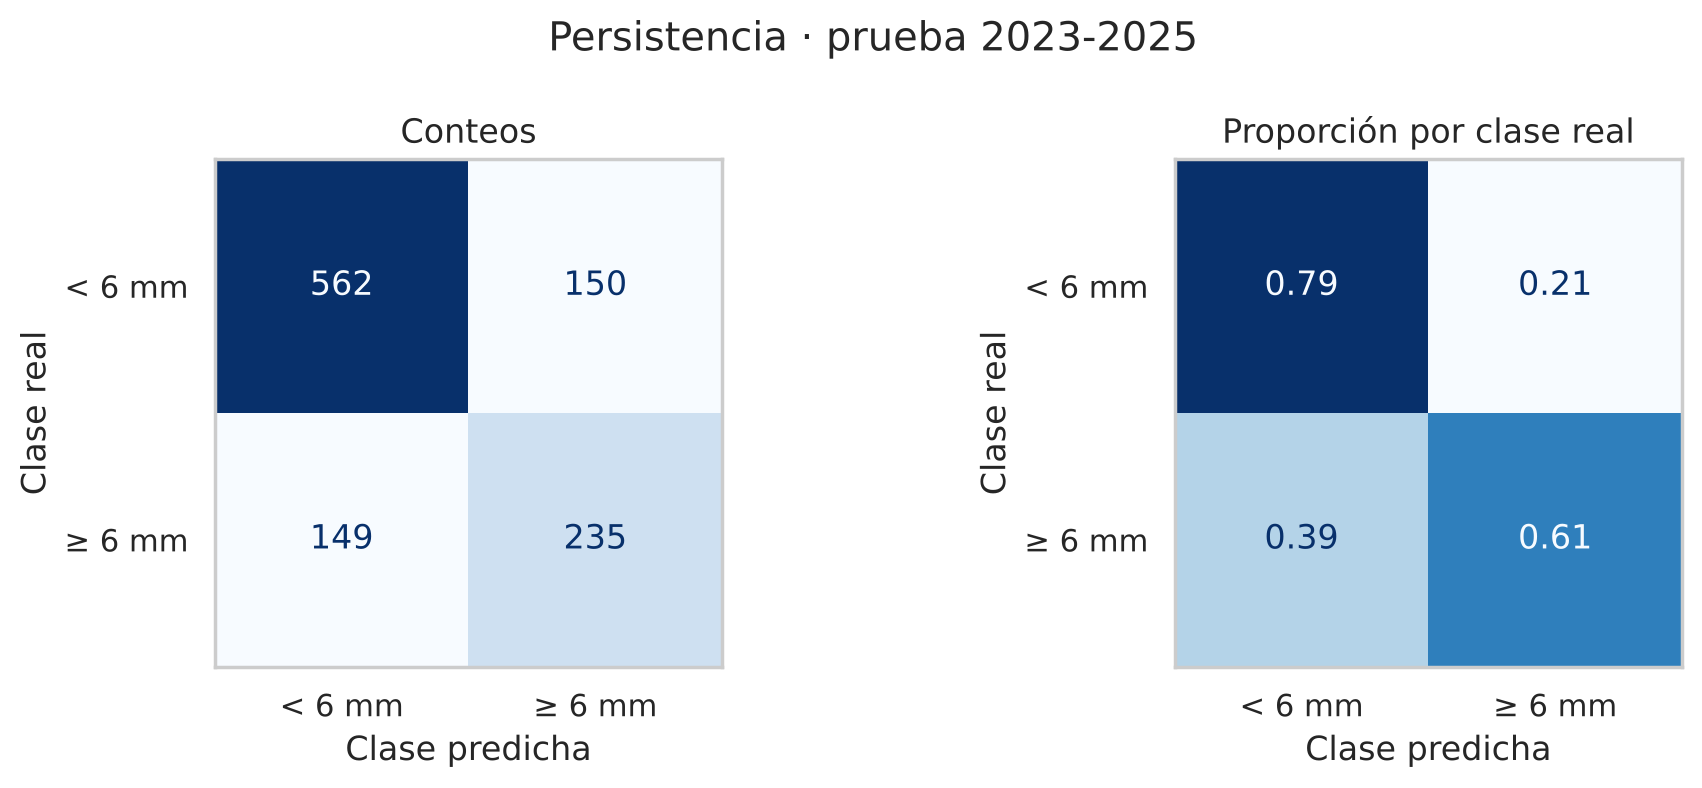

In [10]:
pred_persistencia = (test["precipitacion"] >= 6).astype(int).to_numpy()
pred_siempre = np.ones(len(y_te), dtype=int)
resultados = [metricas("Persistencia", y_te, pred_persistencia),
              metricas("Siempre lluvia", y_te, pred_siempre)]
display(pd.DataFrame(resultados).set_index("Modelo"))
graficar_matriz(y_te, pred_persistencia, "Persistencia · prueba 2023-2025")

In [11]:
# Comprobaciones de las funciones de evaluación
y = np.array([0, 0, 1, 1]); s = np.array([0.1, 0.4, 0.35, 0.8])
assert metricas("t", y, (s > 0.3).astype(int))["Recall"] == 1.0
assert 0.1 <= elegir_umbral(y, s) <= 0.8
assert resultados[0]["Modelo"] == "Persistencia" and resultados[1]["Modelo"] == "Siempre lluvia"
assert resultados[1]["Recall"] == 1.0
print("Funciones de evaluación verificadas.")

Funciones de evaluación verificadas.


## 3. Regresión logística
Modelo lineal que estima la probabilidad de lluvia importante a partir de una combinación ponderada de los predictores. Es el modelo base: sencillo, rápido y sus coeficientes se pueden interpretar. Se ajusta `C`, que controla la regularización: valores pequeños dan coeficientes más pequeños y un modelo más simple.

Regresión logística: mejores hiperparámetros {'C': 0.01}, umbral -0.195, F1 validación 0.633


,C,umbral,F1 validación
0,0.01,-0.195,0.633
1,0.10,0.003,0.632
2,1.00,-0.007,0.630
3,10.00,-0.005,0.630


,Accuracy,Precision,Recall,F1
Modelo,,,,
Regresión logística,0.658,0.507,0.826,0.628


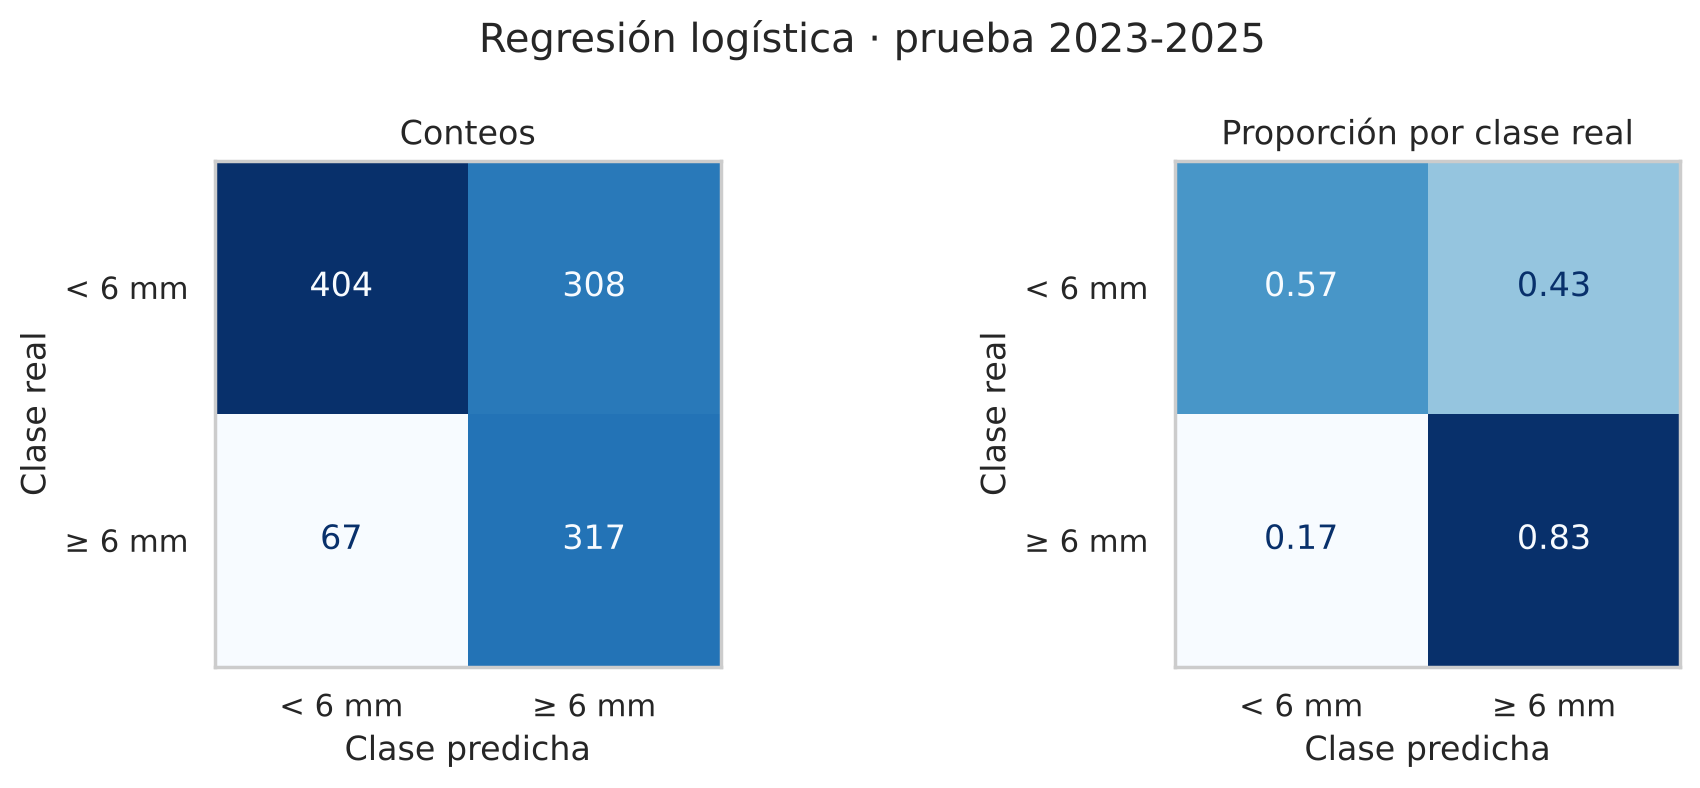

In [12]:
res_log = ajustar_y_evaluar(
    "Regresión logística",
    lambda C: make_pipeline(preprocesador_lineal(),
                            LogisticRegression(C=C, class_weight="balanced", max_iter=2000)),
    [{"C": c} for c in [0.01, 0.1, 1, 10]])
display(res_log["rejilla"])
resultados.append(metricas("Regresión logística", y_te, res_log["pred_te"]))
display(pd.DataFrame(resultados[-1:]).set_index("Modelo"))
graficar_matriz(y_te, res_log["pred_te"], "Regresión logística · prueba 2023-2025")

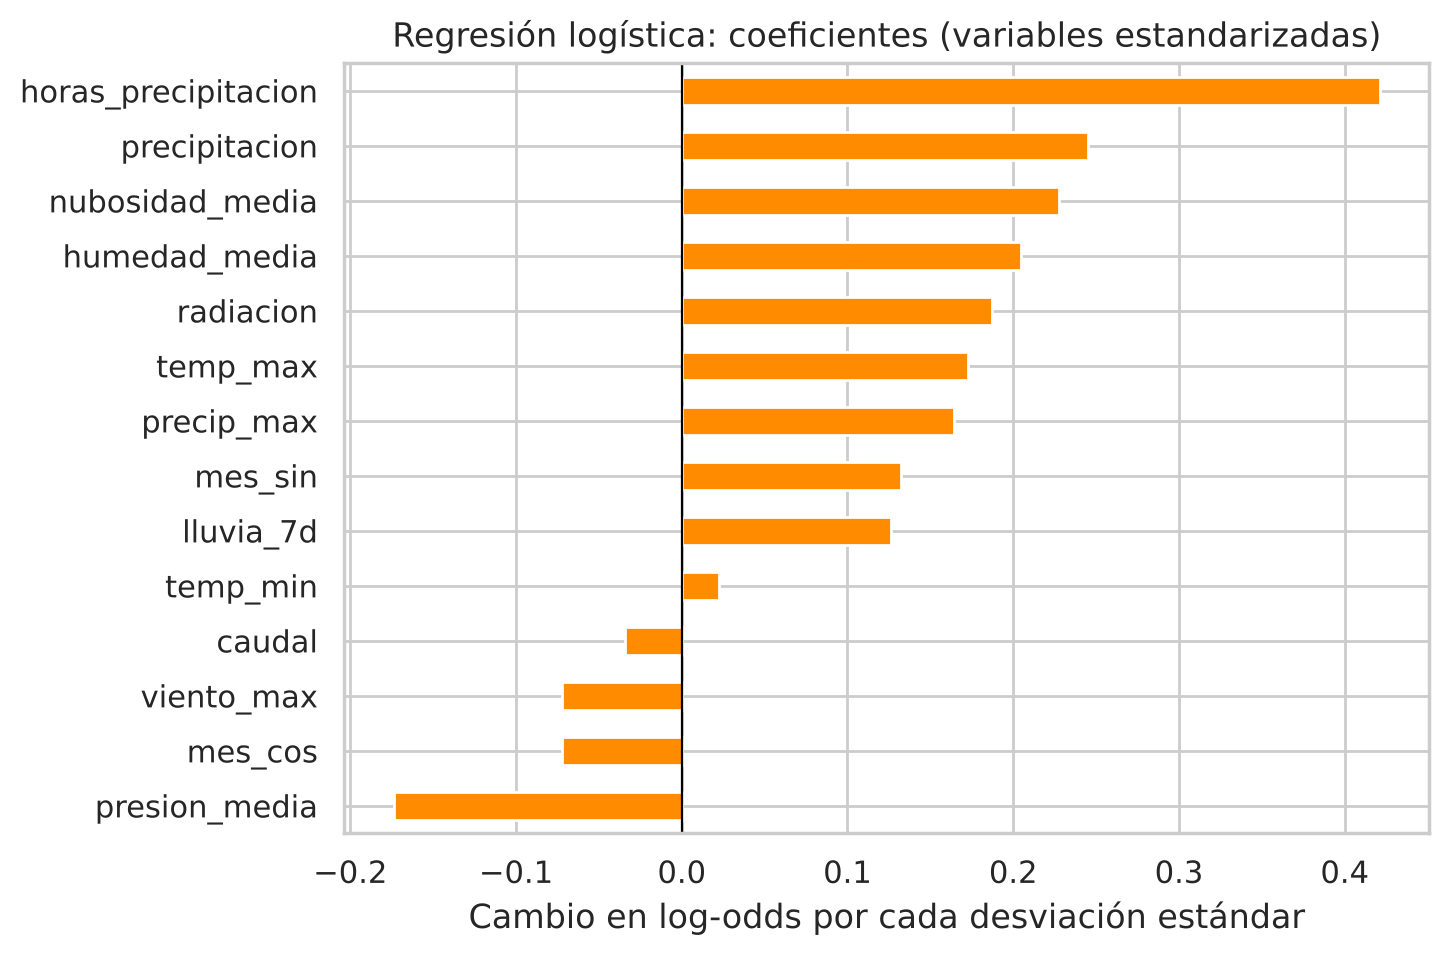

In [13]:
coef_log = pd.Series(res_log["modelo"][-1].coef_[0],
                     index=res_log["modelo"][0].get_feature_names_out()).sort_values()
ax = coef_log.plot.barh(figsize=(7, 5), color="darkorange")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión logística: coeficientes (variables estandarizadas)")
ax.set_xlabel("Cambio en log-odds por cada desviación estándar")
plt.show()

In [14]:
assert res_log["params"]["C"] in [0.01, 0.1, 1, 10]
assert set(np.unique(res_log["pred_te"])) <= {0, 1} and len(res_log["pred_te"]) == len(y_te)
assert resultados[-1]["Modelo"] == "Regresión logística"
print("Regresión logística verificada.")

Regresión logística verificada.


**Interpretación.** El mejor valor es `C = 0,01`, la regularización más fuerte, aunque los cuatro valores dan F1 de validación casi iguales (0,630 a 0,633). En prueba, el modelo detecta **317 de 384 días con lluvia importante (recall 0,83)**, pero genera **308 falsas alarmas** (precisión 0,51). El umbral elegido favorece no perder lluvias a costa de avisar de más. Su F1 (0,63) supera ligeramente a la persistencia (0,61), aunque su accuracy es menor (0,66 frente a 0,73) porque la persistencia acierta más días secos.

Los coeficientes más altos son las **horas de precipitación**, la lluvia de hoy, la nubosidad y la humedad, y la presión tiene el coeficiente negativo más fuerte. Coincide con el EDA. Son asociaciones dentro del modelo y no relaciones causales: con variables tan correlacionadas entre sí, como la radiación y la nubosidad, un coeficiente puede cambiar de signo respecto a su correlación individual.

## 4. Máquinas de soporte vectorial (SVM)
La SVM busca la frontera que separa las dos clases dejando el mayor margen posible. Con **kernel lineal**, la frontera es un hiperplano, como en la logística. Con **kernel RBF**, puede ser curva y captar relaciones no lineales; `gamma` controla qué tan local es esa curvatura. `C` regula cuánto se castigan los errores de entrenamiento. Como trabaja con distancias, necesita variables estandarizadas. El umbral se ajusta sobre la distancia a la frontera (`decision_function`).

SVM: mejores hiperparámetros {'kernel': 'rbf', 'C': 10, 'gamma': 0.01}, umbral -0.028, F1 validación 0.649


,kernel,C,umbral,F1 validación,gamma
9,rbf,10.0,-0.028,0.649,0.01
5,rbf,1.0,0.060,0.644,scale
7,rbf,1.0,0.042,0.644,0.1
6,rbf,1.0,-0.251,0.633,0.01
2,rbf,0.1,-0.156,0.630,scale
4,rbf,0.1,-0.196,0.629,0.1
1,linear,1.0,-0.201,0.629,NaN
0,linear,0.1,-0.245,0.627,NaN
3,rbf,0.1,-0.293,0.626,0.01
8,rbf,10.0,-0.211,0.587,scale


,Accuracy,Precision,Recall,F1
Modelo,,,,
SVM,0.709,0.56,0.794,0.657


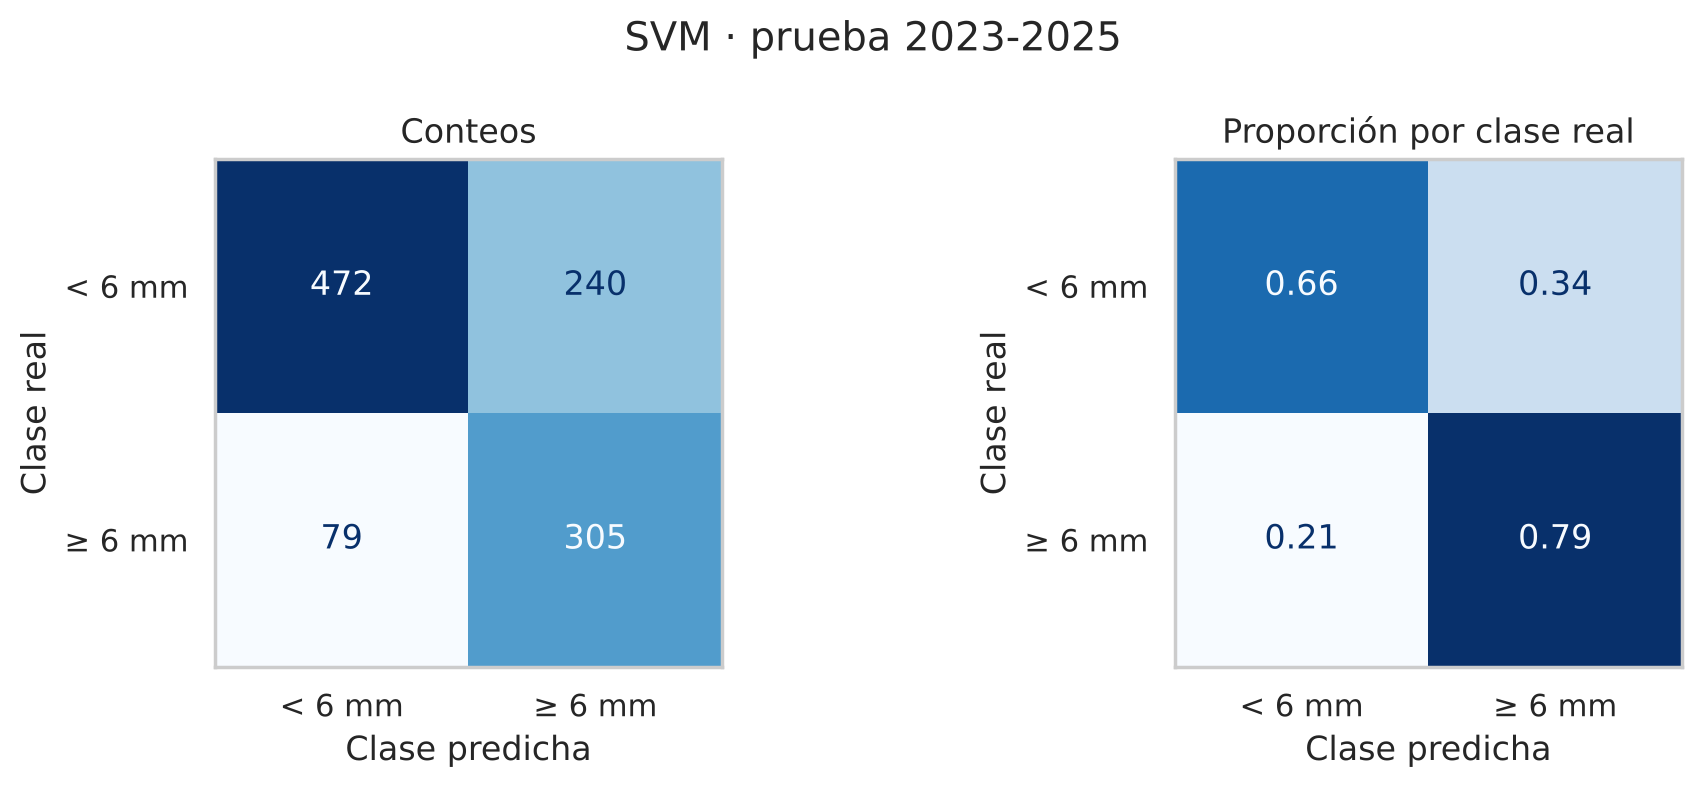

In [15]:
rejilla_svm = ([{"kernel": "linear", "C": c} for c in [0.1, 1]] +
               [{"kernel": "rbf", "C": c, "gamma": g} for c in [0.1, 1, 10] for g in ["scale", 0.01, 0.1]])
res_svm = ajustar_y_evaluar(
    "SVM",
    lambda **p: make_pipeline(preprocesador_lineal(), SVC(class_weight="balanced", **p)),
    rejilla_svm)
display(res_svm["rejilla"])
resultados.append(metricas("SVM", y_te, res_svm["pred_te"]))
display(pd.DataFrame(resultados[-1:]).set_index("Modelo"))
graficar_matriz(y_te, res_svm["pred_te"], "SVM · prueba 2023-2025")

In [16]:
assert res_svm["params"]["kernel"] in ["linear", "rbf"]
assert set(np.unique(res_svm["pred_te"])) <= {0, 1} and len(res_svm["pred_te"]) == len(y_te)
assert resultados[-1]["Modelo"] == "SVM"
print("SVM verificada.")

SVM verificada.


**Interpretación.** La mejor combinación es **kernel RBF con `C = 10` y `gamma = 0,01`** (F1 de validación 0,649). Los kernels lineales quedan en 0,63, el mismo nivel de la logística, así que la frontera curva sí aporta. Con `C = 10` y `gamma` 0,1 o "scale", el F1 baja a 0,55 a 0,59: la frontera se ajusta demasiado al entrenamiento y generaliza peor. En prueba, la SVM detecta **305 de 384 lluvias importantes (recall 0,79)** con **240 falsas alarmas**, 68 menos que la logística. Su F1 es 0,66 y su accuracy 0,71. La SVM no entrega coeficientes interpretables con kernel RBF, lo que es su principal desventaja frente a los otros dos modelos.

## 5. Árbol de decisión
El árbol divide los días con preguntas sucesivas del tipo "¿la lluvia de hoy es mayor a X mm?", hasta llegar a hojas con una proporción de días lluviosos. Es el modelo más fácil de explicar y no necesita escalado, por eso usa el mes tal cual. Sin límites, un árbol memoriza el entrenamiento (sobreajuste). Por eso se ajustan `max_depth`, la profundidad máxima, y `min_samples_leaf`, el mínimo de días por hoja.

Árbol de decisión: mejores hiperparámetros {'max_depth': 6, 'min_samples_leaf': 50}, umbral 0.606, F1 validación 0.624


,max_depth,min_samples_leaf,umbral,F1 validación
10,6,50,0.606,0.624
13,8,50,0.606,0.624
3,4,20,0.604,0.623
4,4,50,0.604,0.617
5,4,100,0.537,0.616
9,6,20,0.591,0.612
2,3,100,0.483,0.605
1,3,50,0.509,0.605


,Accuracy,Precision,Recall,F1
Modelo,,,,
Árbol de decisión,0.705,0.579,0.583,0.581


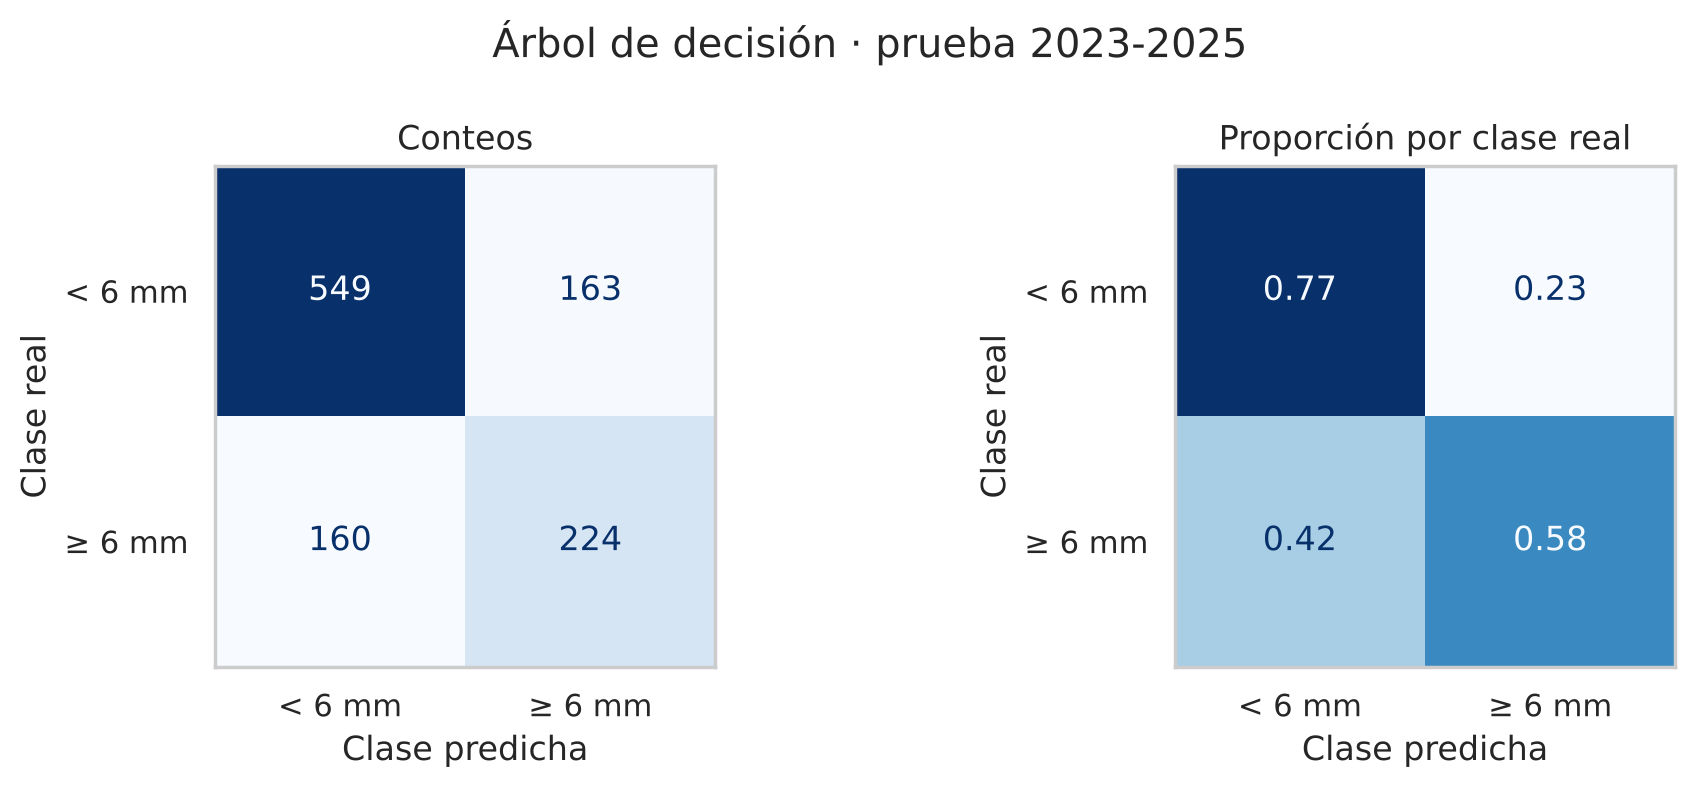

In [17]:
res_arbol = ajustar_y_evaluar(
    "Árbol de decisión",
    lambda **p: DecisionTreeClassifier(class_weight="balanced", random_state=42, **p),
    [{"max_depth": d, "min_samples_leaf": h} for d in [3, 4, 5, 6, 8] for h in [20, 50, 100]])
display(res_arbol["rejilla"].head(8))
resultados.append(metricas("Árbol de decisión", y_te, res_arbol["pred_te"]))
display(pd.DataFrame(resultados[-1:]).set_index("Modelo"))
graficar_matriz(y_te, res_arbol["pred_te"], "Árbol de decisión · prueba 2023-2025")

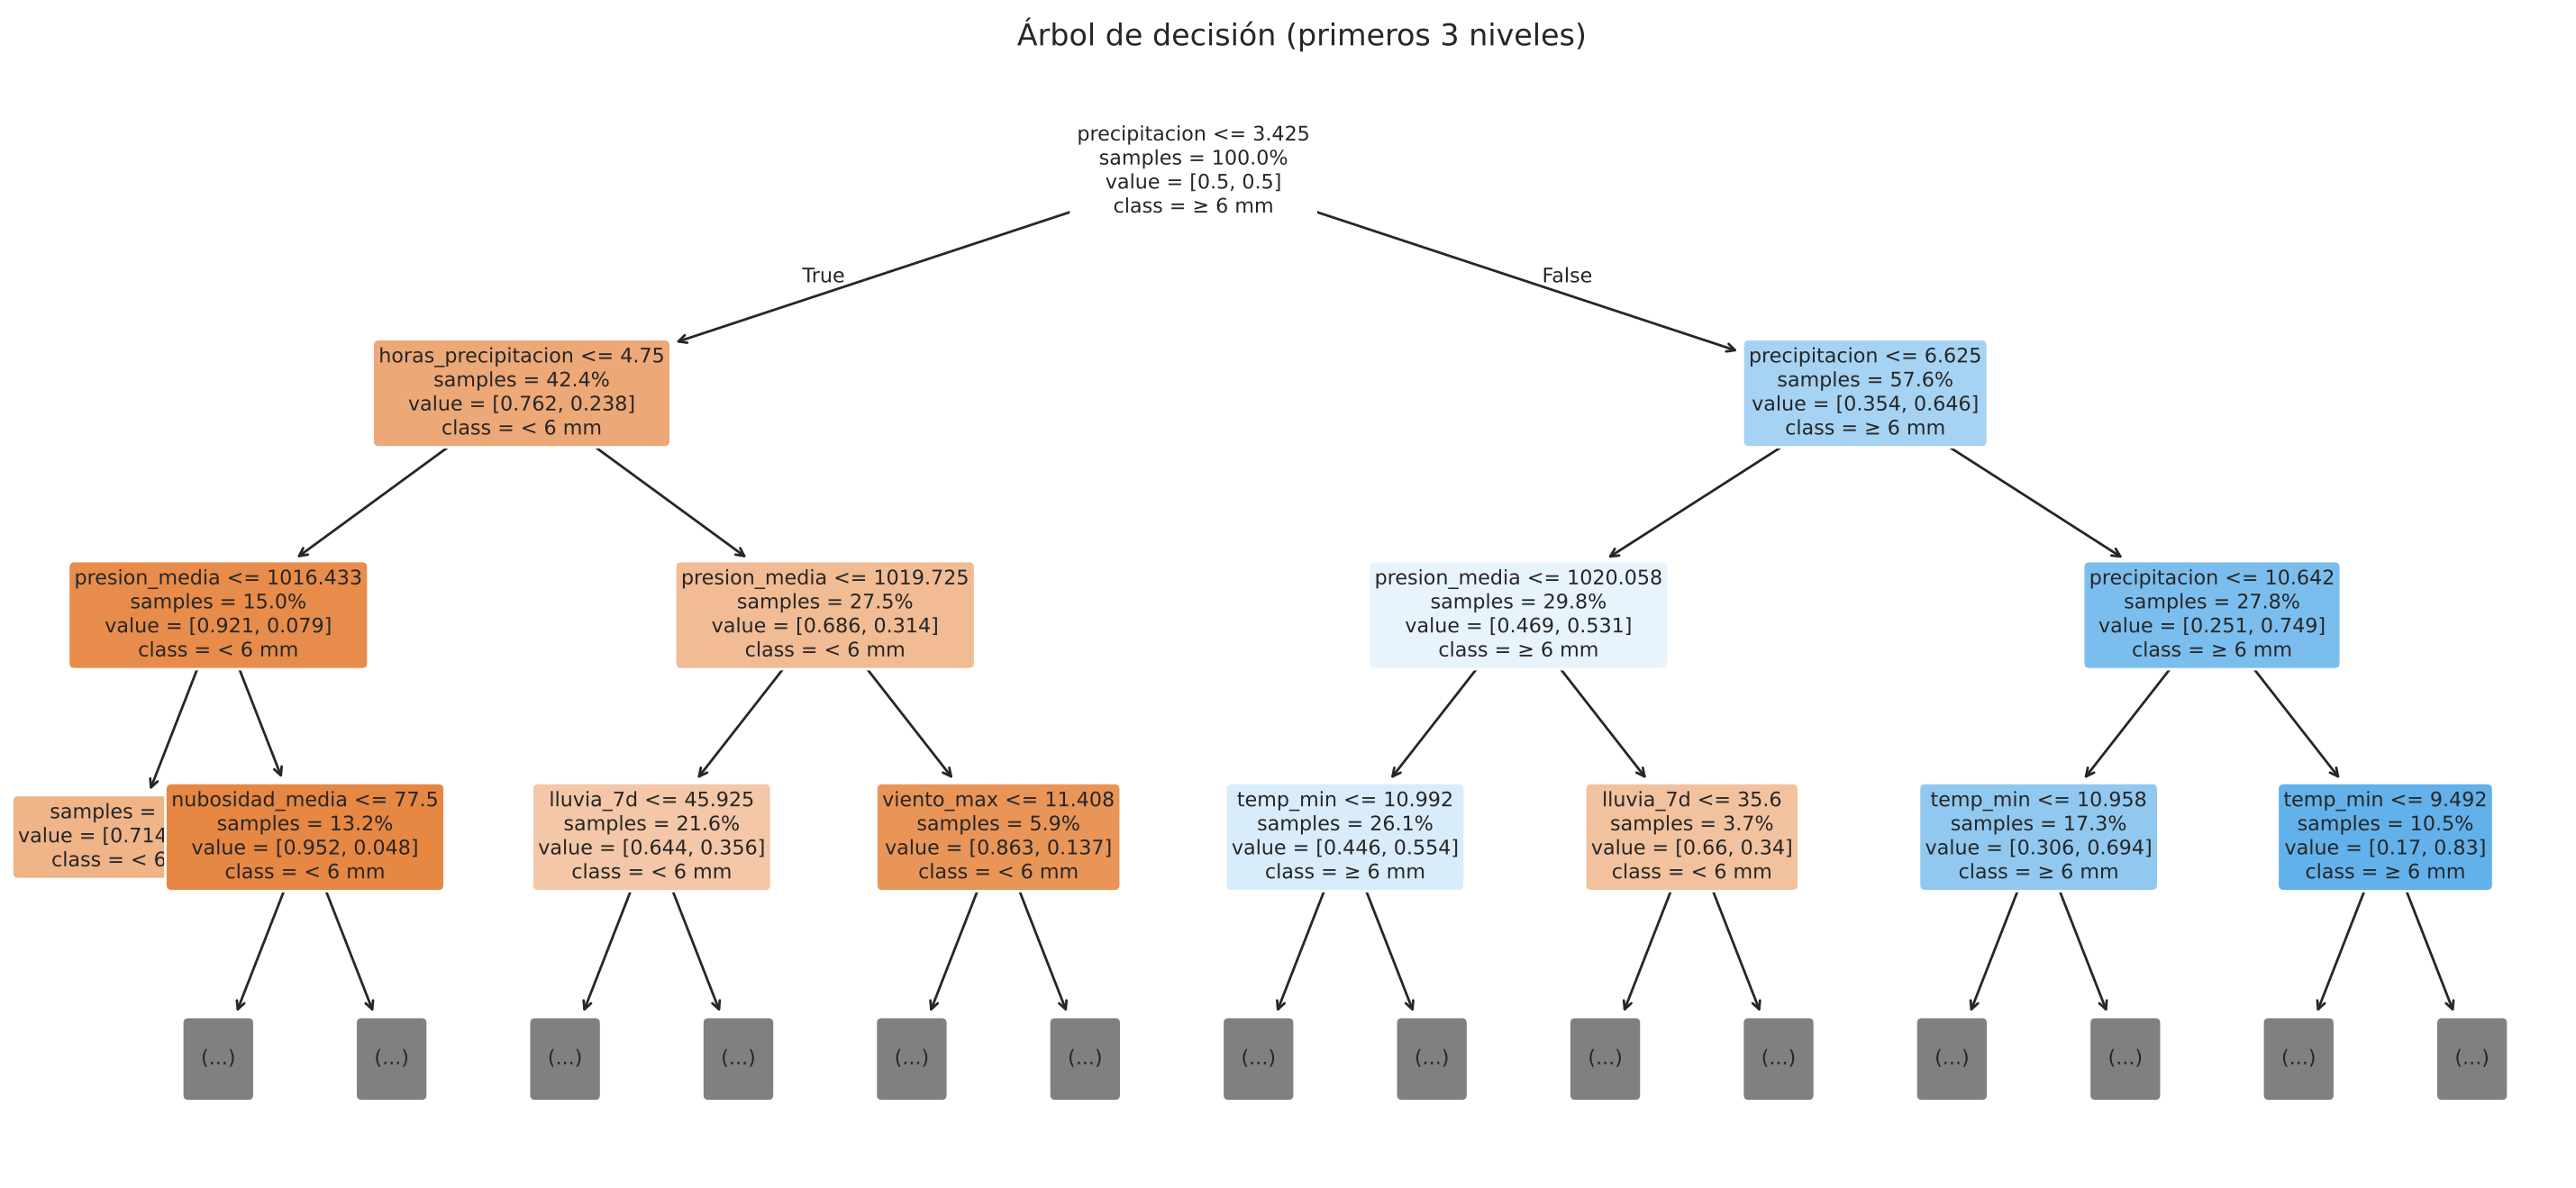

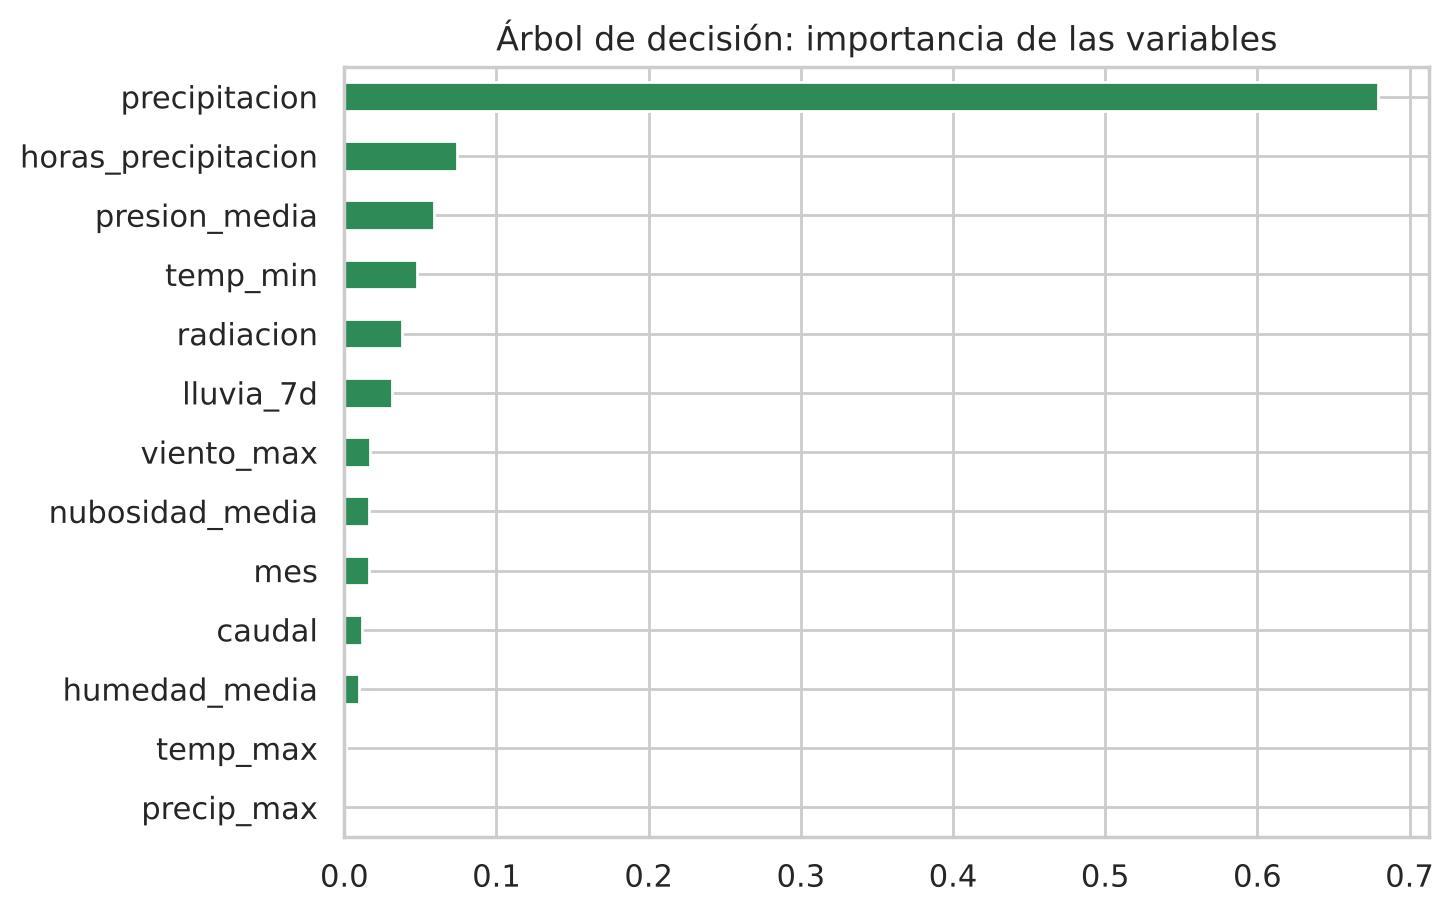

In [18]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(res_arbol["modelo"], max_depth=3, feature_names=PREDICTORES, class_names=["< 6 mm", "≥ 6 mm"],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=8, ax=ax)
ax.set_title("Árbol de decisión (primeros 3 niveles)")
plt.show()

importancias = pd.Series(res_arbol["modelo"].feature_importances_, index=PREDICTORES).sort_values()
ax = importancias.plot.barh(figsize=(7, 5), color="seagreen")
ax.set_title("Árbol de decisión: importancia de las variables")
plt.show()

In [19]:
assert res_arbol["modelo"].get_depth() <= 8
assert set(np.unique(res_arbol["pred_te"])) <= {0, 1} and len(res_arbol["pred_te"]) == len(y_te)
assert resultados[-1]["Modelo"] == "Árbol de decisión"
print("Árbol de decisión verificado.")

Árbol de decisión verificado.


**Interpretación.** El mejor árbol tiene **profundidad 6 y al menos 50 días por hoja** (F1 de validación 0,624). Con profundidad 8 se obtiene el mismo F1, así que se queda el árbol más simple. Las reglas se leen directamente. La primera pregunta es si la lluvia promedio de la cuenca hoy supera **3,4 mm**. Si no la supera, el árbol mira las horas de lluvia y la presión: pocas horas de lluvia y presión baja llevan a "no habrá lluvia importante". Si la supera, vuelve a dividir por la cantidad de lluvia (6,6 y 10,6 mm). La lluvia de hoy concentra el **68 % de la importancia**, seguida de las horas de precipitación y la presión.

En prueba, el árbol es el más equilibrado entre precisión y recall (0,58 y 0,58), pero su **F1 de 0,58 queda por debajo de la persistencia (0,61)**. En la práctica, el árbol hace algo parecido a la persistencia con cortes fijos de lluvia, y al dividir los datos en hojas pierde parte de la información fina que sí aprovechan la logística y la SVM.

## 6. Comparación e interpretación de resultados
La tabla reúne las métricas de prueba (2023 a 2025) de los tres modelos y de las dos referencias. La columna `F1_validacion` es la que decide el modelo final: se elige con 2021 a 2022 para que la decisión no dependa del conjunto con el que se evalúa.

In [20]:
f1_val = {"Regresión logística": res_log["f1_val"], "SVM": res_svm["f1_val"], "Árbol de decisión": res_arbol["f1_val"]}
tabla_final = pd.DataFrame(resultados).set_index("Modelo")
tabla_final["F1_validacion"] = pd.Series(f1_val)
MEJOR = tabla_final.drop(["Persistencia", "Siempre lluvia"])["F1_validacion"].idxmax()
RES = {"Regresión logística": res_log, "SVM": res_svm, "Árbol de decisión": res_arbol}
display(tabla_final.round(3))

f1_mejor = tabla_final.loc[MEJOR, "F1"]
print(f"Modelo seleccionado: {MEJOR}")
print(f"F1 en prueba: {f1_mejor:.3f} | vs. persistencia: {f1_mejor - tabla_final.loc['Persistencia', 'F1']:+.3f} "
      f"| vs. siempre lluvia: {f1_mejor - tabla_final.loc['Siempre lluvia', 'F1']:+.3f}")

,Accuracy,Precision,Recall,F1,F1_validacion
Modelo,,,,,
Persistencia,0.727,0.610,0.612,0.611,NaN
Siempre lluvia,0.350,0.350,1.000,0.519,NaN
Regresión logística,0.658,0.507,0.826,0.628,0.633
SVM,0.709,0.560,0.794,0.657,0.649
Árbol de decisión,0.705,0.579,0.583,0.581,0.624


Modelo seleccionado: SVM
F1 en prueba: 0.657 | vs. persistencia: +0.045 | vs. siempre lluvia: +0.138


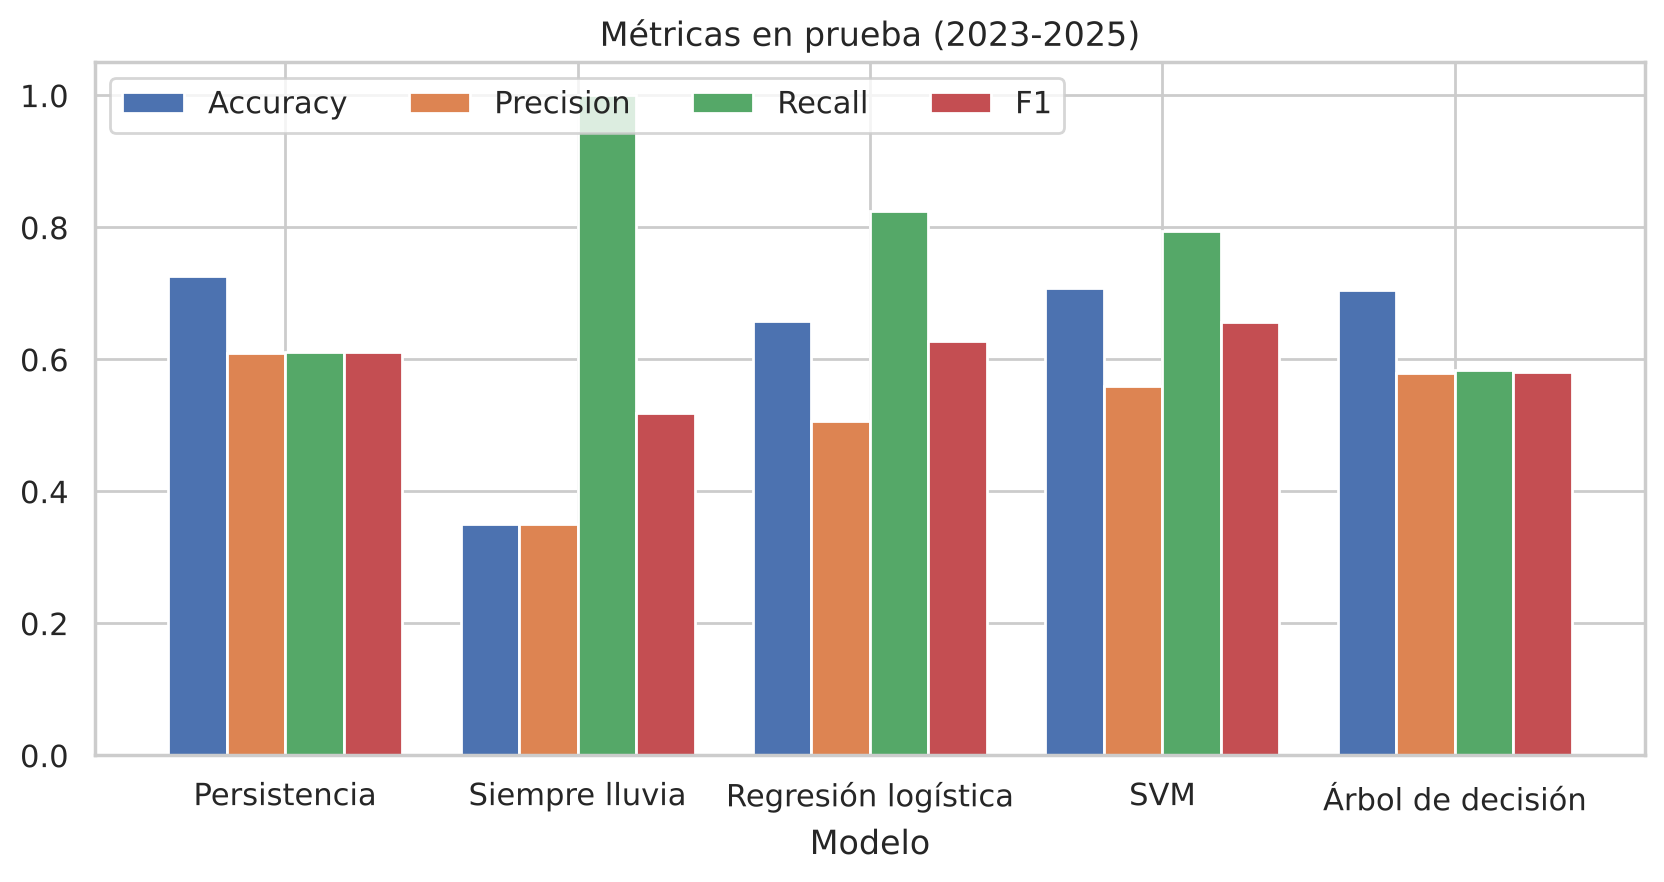

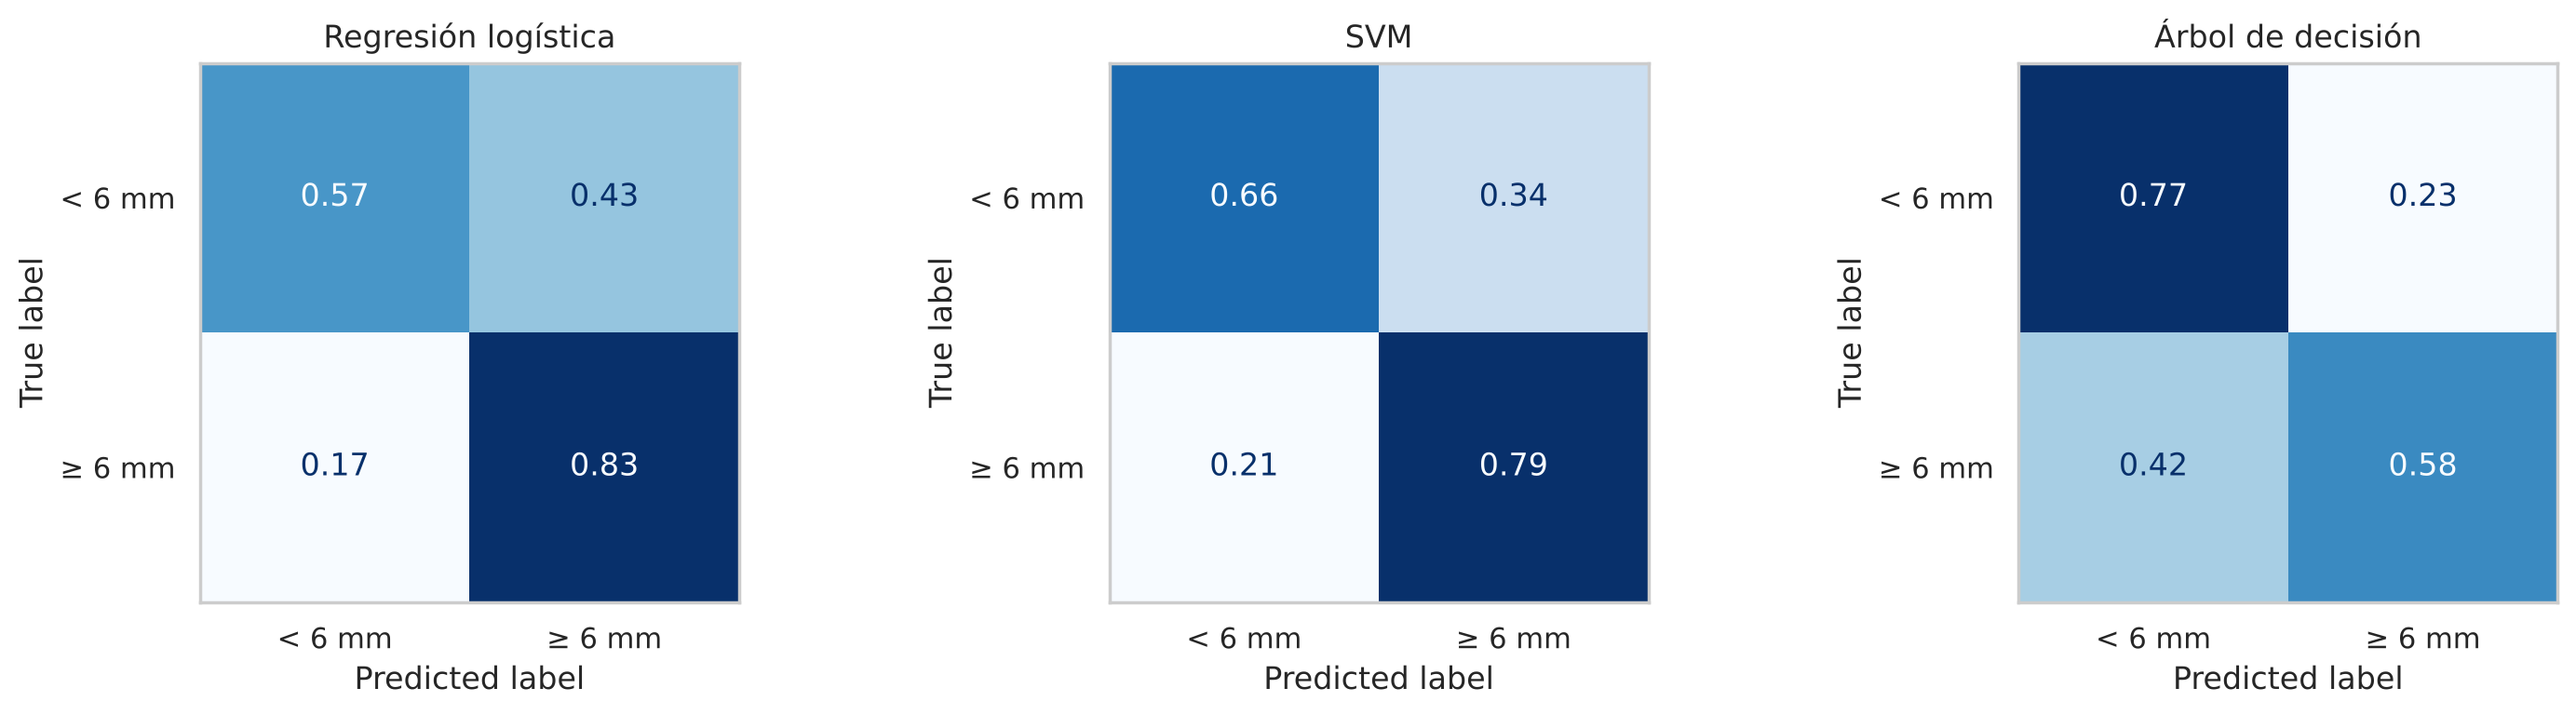

In [21]:
ax = tabla_final[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylim(0, 1.05)
ax.set_title("Métricas en prueba (2023-2025)")
ax.legend(loc="upper left", ncol=4)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, res) in zip(axes, [("Regresión logística", res_log), ("SVM", res_svm), ("Árbol de decisión", res_arbol)]):
    ConfusionMatrixDisplay.from_predictions(y_te, res["pred_te"], normalize="true", values_format=".2f",
                                            display_labels=["< 6 mm", "≥ 6 mm"], ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [22]:
assert len(tabla_final) == 5
assert MEJOR in ["Regresión logística", "SVM", "Árbol de decisión"]
assert MEJOR == tabla_final.drop(["Persistencia", "Siempre lluvia"])["F1_validacion"].idxmax()
print("Comparación verificada.")

Comparación verificada.


**Modelo seleccionado: SVM con kernel RBF.** Tiene el mayor F1 tanto en validación (0,649) como en prueba (0,657), y el orden de los tres modelos se mantiene entre ambos periodos, lo que da confianza en la elección. Supera a la persistencia en **4,5 puntos de F1**: detecta 305 de 384 lluvias importantes, frente a 235 de la persistencia. También supera a "siempre lluvia" en 13,8 puntos, así que su F1 no viene de anunciar lluvia todos los días. Era el punto pendiente del Avance I, donde la logística quedaba por debajo de esa referencia en F1.

**Lo que se sacrifica.** La persistencia sigue teniendo mejor accuracy (0,73 frente a 0,71) y más precisión (0,61 frente a 0,56), porque comete menos falsas alarmas. La SVM elige a propósito avisar de más para perder menos lluvias. Para Mazar, una lluvia importante no anticipada cuesta más que una falsa alarma, así que ese intercambio es razonable. La regresión logística detecta incluso más lluvias (recall 0,83), pero con 68 falsas alarmas adicionales, y el árbol es el más fácil de explicar, pero no supera a la persistencia. La principal desventaja de la SVM es que no ofrece coeficientes ni reglas legibles. Para explicar qué variables pesan, el equipo se apoya en los coeficientes de la logística y en el árbol, que coinciden en dar peso a la lluvia de hoy, a las horas de lluvia y a la presión.

### 6.1 AUC como métrica complementaria
En la revisión del Avance I se observó que el AUC de 0,65 estaba muy cerca de 0,5, que equivale a adivinar. El AUC no depende del umbral: mide qué tan bien separa cada modelo los días con y sin lluvia importante usando su puntaje. No se usa para elegir el modelo, solo para comparar con el Avance I.

In [23]:
auc = pd.Series({nombre: roc_auc_score(y_te, puntajes(res["modelo"], X_te)) for nombre, res in RES.items()})
auc["Persistencia (lluvia de hoy)"] = roc_auc_score(y_te, test["precipitacion"])
auc.round(3).to_frame("AUC prueba")

,AUC prueba
Regresión logística,0.780
SVM,0.786
Árbol de decisión,0.742
Persistencia (lluvia de hoy),0.769


La SVM tiene el AUC más alto, 0,79, y la logística queda muy cerca, con 0,78. Los dos están lejos de 0,5 y por encima del 0,65 del Avance I, aunque ese valor se obtuvo con el dataset anterior. Sin embargo, la lluvia de hoy por sí sola ya logra 0,77, así que la capacidad de separar días casi no cambia frente a la persistencia. La ventaja de la SVM está sobre todo en el umbral elegido en validación, que le permite detectar muchas más lluvias importantes. El árbol, con 0,74, separa peor que la lluvia de hoy sola, igual que pasaba con su F1.

## 7. Avances y sugerencias de las sesiones 1 a 1

**Avances del equipo.**
- **Avance I de Machine Learning:** se trabajó con dos zonas, Coca Codo Sinclair y Mazar, un punto por zona y un umbral de 5 mm. Se probaron una regresión lineal y una regresión logística, y la logística no superaba con claridad a las referencias simples.
- **Big Data, Entregable 1 actualizado y Parte 2:** el equipo se concentró en la cuenca del río Paute, que alimenta a Mazar. Se integraron 6 puntos y el caudal del río, y el umbral de 6 mm se justificó con la respuesta del caudal.
- **Este avance:** se entrenan tres algoritmos de clasificación con una partición en tres periodos, ajuste de hiperparámetros y umbral de decisión elegido en validación.

**Sugerencias recibidas y cambios realizados.**

| Sesión | Sugerencia recibida | Cambio realizado | Estado | Dónde se ve |
|---|---|---|---|---|
| Machine Learning, revisión del Avance I | Aumentar los datos | Se pasó de un punto por zona a 6 puntos de la misma cuenca, 24.108 registros de clima, más 4.018 días de caudal. Se agregaron `precip_max`, `lluvia_7d` y `caudal` | Hecho | Sección 1 |
| Machine Learning, revisión del Avance I | Probar otros modelos y técnicas | Además de la logística se entrenan una SVM con kernel lineal y RBF y un árbol de decisión, con ajuste de hiperparámetros, clases balanceadas y umbral ajustado | Hecho | Secciones 2 a 5 |
| Machine Learning, revisión del Avance I | Elegir una sola métrica principal | El F1 de la clase positiva es la única métrica que se optimiza. Accuracy, precision y recall se reportan porque las pide el enunciado | Hecho | Secciones 2 y 6 |
| Machine Learning, revisión del Avance I | El AUC de 0,65 estaba cerca de adivinar | El AUC se calcula como métrica complementaria y sube a 0,79 con la SVM | Hecho | Sección 6.1 |
| Machine Learning, revisión del Avance I | Los errores de la matriz de confusión eran altos, 25 % y 46 %; lo ideal es acercarse a 10 o 15 % | Con la SVM quedan 21 % de lluvias no detectadas y 34 % de falsas alarmas. Mejora el primer error, pero todavía no llega al nivel sugerido | Parcial | Secciones 4 y 6 |
| Machine Learning, revisión del Avance I | En regresión la lluvia nunca es negativa, conviene usar MAE | La regresión no forma parte de este avance, que pide clasificación. Se retomará con MAE y modelos que no den valores negativos | Pendiente | Sección 8 |
| Machine Learning, revisión del Avance I | Series de tiempo, opcional | Se respeta el orden en el tiempo en toda la evaluación y `lluvia_7d` y `caudal` resumen los días anteriores | Parcial | Sección 1 |
| Big Data, sesión del 22/10 | Usar varios puntos de la zona y agrupar por zona y fecha, y quedarse con una sola hidroeléctrica | Solo Mazar, con 6 puntos agrupados por fecha | Hecho | Sección 1 |
| Big Data, sesión del 22/10 | Ver si el caudal se relaciona con la lluvia y si los datos sirven antes del modelo | Se agregó el caudal y con él se justificó el umbral de 6 mm | Hecho | Sección 1 |
| Big Data, sesión del 22/10 | Expresar el resultado como probabilidad baja, media o alta | Los modelos entregan un puntaje. Los niveles de probabilidad se presentarán en el dashboard | Pendiente | Sección 8 |

## 8. Conclusiones

In [24]:
cm_svm = confusion_matrix(y_te, RES[MEJOR]["pred_te"])
cm_per = confusion_matrix(y_te, pred_persistencia)
print(f"Modelo final: {MEJOR} {RES[MEJOR]['params']}")
print(f"F1 prueba: {tabla_final.loc[MEJOR, 'F1']:.3f} (persistencia {tabla_final.loc['Persistencia', 'F1']:.3f})")
print(f"Lluvias importantes detectadas: {cm_svm[1, 1]} de {cm_svm[1].sum()} (persistencia {cm_per[1, 1]})")
print(f"Falsas alarmas: {cm_svm[0, 1]} (persistencia {cm_per[0, 1]})")

Modelo final: SVM {'kernel': 'rbf', 'C': 10, 'gamma': 0.01}
F1 prueba: 0.657 (persistencia 0.611)
Lluvias importantes detectadas: 305 de 384 (persistencia 235)
Falsas alarmas: 240 (persistencia 150)


In [25]:
# Las cifras citadas en los textos del notebook coinciden con las salidas
t = tabla_final.round(3)
assert MEJOR == "SVM" and res_svm["params"] == {"kernel": "rbf", "C": 10, "gamma": 0.01}
assert (t.loc["SVM", "F1"], t.loc["Persistencia", "F1"], t.loc["Regresión logística", "F1"],
        t.loc["Árbol de decisión", "F1"]) == (0.657, 0.611, 0.628, 0.581)
assert (cm_svm[1, 1], cm_svm[1].sum(), cm_svm[0, 1], cm_per[1, 1]) == (305, 384, 240, 235)
assert confusion_matrix(y_te, res_log["pred_te"])[[1, 0], [1, 1]].tolist() == [317, 308]
assert res_arbol["params"] == {"max_depth": 6, "min_samples_leaf": 50}
assert RES[MEJOR] is res_svm
assert (res_svm["rejilla"].query("`F1 validación` < 0.6")["C"] == 10).all()
assert set(importancias.nlargest(3).index) == {"precipitacion", "horas_precipitacion", "presion_media"}
print("Cifras del texto verificadas.")

Cifras del texto verificadas.


Con los datos de hoy de la cuenca del Paute se puede anticipar si mañana lloverán 6 mm o más mejor que con la regla de persistencia, evaluando siempre con días posteriores a los de entrenamiento. De los tres algoritmos, la **SVM con kernel RBF** es la elegida: logra el mayor F1 en validación y en prueba (0,66 frente a 0,61 de la persistencia) y detecta 305 de las 384 lluvias importantes de 2023 a 2025, a cambio de 240 falsas alarmas. La regresión logística queda cerca y es la más fácil de interpretar. El árbol de decisión, aunque legible, no supera a la persistencia. En los modelos interpretables, las variables que más pesan son la lluvia de hoy, las horas de lluvia y la presión.

Los resultados tienen límites. Es un prototipo académico con datos de reanálisis de Open-Meteo, no con estaciones de medición, y se evaluó un solo corte temporal. La mejora sobre la persistencia es moderada y se paga con menor precisión. Como siguientes pasos, se plantean validar con varios cortes temporales, probar modelos de conjunto (Random Forest y Gradient Boosting, listados en el avance de Big Data) e incorporar el modelo final al dashboard con sus probabilidades y limitaciones.